# Prediksi Risiko Stroke menggunakan Machine Learning

**Nama:** AZHAR ZUHRO

**Domain:** Kesehatan  

**Metode:** Klasifikasi (Binary Classification)

**Dataset:** Stroke Prediction Dataset  

**Sumber:** https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset  

**Jumlah Data:** 5.110 sampel × 12 fitur

## 1. Import Library

Mengimpor semua library yang dibutuhkan untuk analisis data, visualisasi, pemodelan, dan evaluasi model.

In [1]:
import numpy as np
import pandas as pd
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('seaborn-v0_8-whitegrid')
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, ConfusionMatrixDisplay
)

print('Semua library berhasil diimpor!')
print(f'Pandas  : {pd.__version__}')
print(f'NumPy   : {np.__version__}')

Semua library berhasil diimpor!
Pandas  : 2.2.2
NumPy   : 2.0.2


## 2. Data Understanding

### 2.1 Load Dataset

Dataset dapat diunduh dari Kaggle:
https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

Setelah diunduh, simpan file `healthcare-dataset-stroke-data.csv` di direktori yang sama dengan notebook ini.

In [2]:
# Load dataset
df = pd.read_csv('/content/healthcare-dataset-stroke-data.csv')

print('      INFORMASI UMUM DATASET')
print(f'  Jumlah Sampel  : {df.shape[0]:,}')
print(f'  Jumlah Kolom   : {df.shape[1]}')
print(f'  Ukuran Dataset : {df.memory_usage(deep=True).sum() / 1024:.1f} KB')
print()
df.head(10)

      INFORMASI UMUM DATASET
  Jumlah Sampel  : 5,110
  Jumlah Kolom   : 12
  Ukuran Dataset : 1657.7 KB



,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
5,56669,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1
6,53882,Male,74.0,1,1,Yes,Private,Rural,70.09,27.4,never smoked,1
7,10434,Female,69.0,0,0,No,Private,Urban,94.39,22.8,never smoked,1
8,27419,Female,59.0,0,0,Yes,Private,Rural,76.15,NaN,Unknown,1
9,60491,Female,78.0,0,0,Yes,Private,Urban,58.57,24.2,Unknown,1


### 2.1.1 Inspeksi Tipe Data

Melihat tipe data setiap kolom dan jumlah non-null values untuk memahami struktur dataset secara menyeluruh.

In [3]:
# Tipe data setiap kolom
print('Informasi Tipe Data:')
df.info()

Informasi Tipe Data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


### 2.1.2 Statistik Deskriptif

Menampilkan ringkasan statistik fitur numerik (mean, std, min, max, quartile) untuk mendeteksi potensi outlier dan memahami skala setiap fitur.

In [4]:
# Statistik deskriptif
print('Statistik Deskriptif Fitur Numerik:')
df.describe().round(2)

Statistik Deskriptif Fitur Numerik:


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.00,5110.00,5110.0,5110.00,5110.00,4909.00,5110.00
mean,36517.83,43.23,0.1,0.05,106.15,28.89,0.05
std,21161.72,22.61,0.3,0.23,45.28,7.85,0.22
min,67.00,0.08,0.0,0.00,55.12,10.30,0.00
25%,17741.25,25.00,0.0,0.00,77.24,23.50,0.00
50%,36932.00,45.00,0.0,0.00,91.88,28.10,0.00
75%,54682.00,61.00,0.0,0.00,114.09,33.10,0.00
max,72940.00,82.00,1.0,1.00,271.74,97.60,1.00


### 2.2 Pengecekan Kondisi Data

In [5]:
# Cek Missing Values
print('     CEK MISSING VALUES')
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing (%)': missing_pct})
print(missing_df[missing_df['Missing Count'] > 0])
print(f'\nTotal missing values: {missing.sum()}')

# Cek Duplikasi
print('     CEK DUPLIKASI DATA')
print(f'Jumlah baris duplikat: {df.duplicated().sum()}')

# Distribusi Target
print('     DISTRIBUSI TARGET')
print(df['stroke'].value_counts())
print()
print(df['stroke'].value_counts(normalize=True).mul(100).round(2).astype(str) + ' %')

     CEK MISSING VALUES
     Missing Count  Missing (%)
bmi            201         3.93

Total missing values: 201
     CEK DUPLIKASI DATA
Jumlah baris duplikat: 0
     DISTRIBUSI TARGET
stroke
0    4861
1     249
Name: count, dtype: int64

stroke
0    95.13 %
1     4.87 %
Name: proportion, dtype: object


### 2.3 Exploratory Data Analysis (EDA)

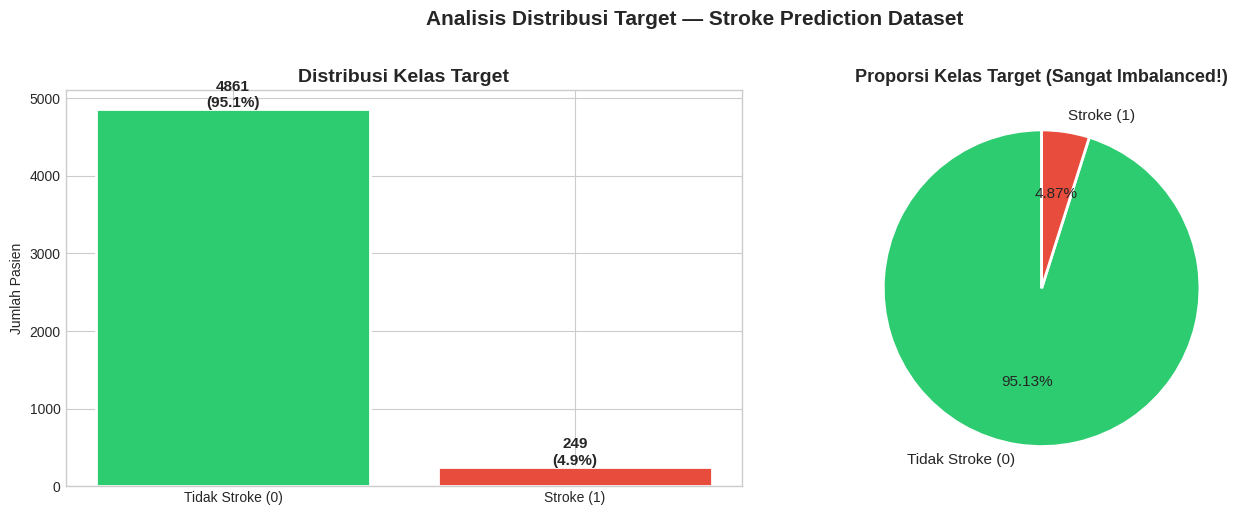

In [6]:
# Distribusi Target
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

stroke_counts = df['stroke'].value_counts()
colors = ['#2ecc71', '#e74c3c']
labels = ['Tidak Stroke (0)', 'Stroke (1)']

bars = axes[0].bar(labels, stroke_counts.values, color=colors,
                   edgecolor='white', linewidth=2)
axes[0].set_title('Distribusi Kelas Target', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Jumlah Pasien')
for bar, count in zip(bars, stroke_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
                 f'{count}\n({count/len(df)*100:.1f}%)',
                 ha='center', fontweight='bold', fontsize=11)

axes[1].pie(stroke_counts.values, labels=labels, colors=colors,
            autopct='%1.2f%%', startangle=90, textprops={'fontsize': 11},
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Proporsi Kelas Target (Sangat Imbalanced!)',
                  fontsize=13, fontweight='bold')

plt.suptitle('Analisis Distribusi Target — Stroke Prediction Dataset',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('01_target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

#### EDA 2: Distribusi Usia berdasarkan Status Stroke

Usia adalah faktor risiko stroke yang paling dikenal secara medis. Visualisasi KDE dan boxplot digunakan untuk membandingkan distribusi usia antara kelompok stroke dan tidak stroke.

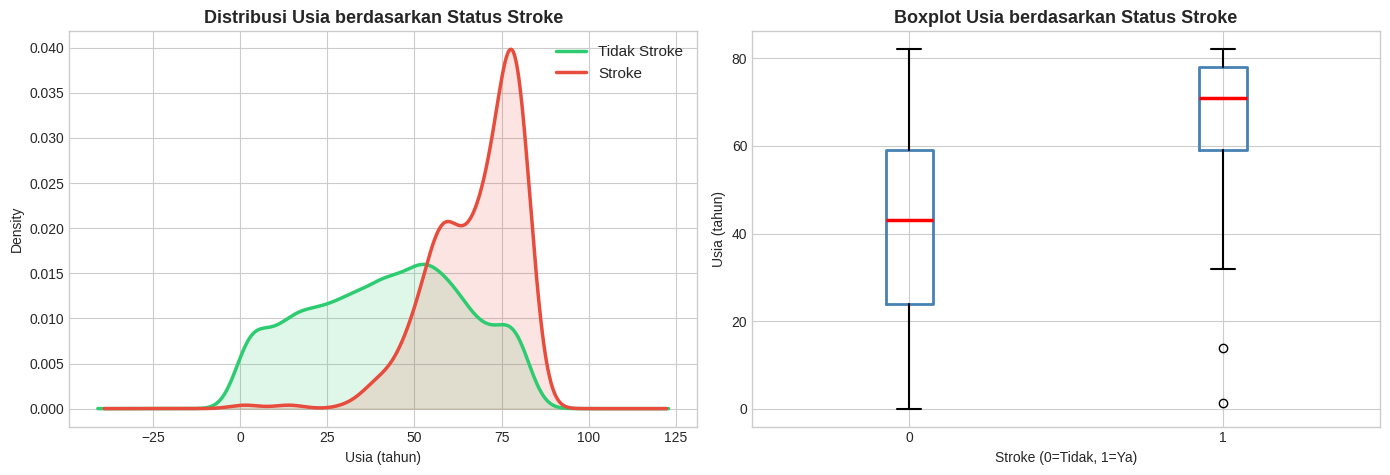

Rata-rata usia pasien TIDAK stroke : 42.0 tahun
Rata-rata usia pasien STROKE       : 67.7 tahun


In [7]:
# Distribusi Usia berdasarkan Target
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# KDE Plot
for val, color, label in zip([0, 1], ['#2ecc71', '#e74c3c'],
                              ['Tidak Stroke', 'Stroke']):
    df[df['stroke']==val]['age'].plot(kind='kde', ax=axes[0],
                                      color=color, linewidth=2.5, label=label)
    axes[0].fill_between(axes[0].lines[-1].get_xdata(),
                          axes[0].lines[-1].get_ydata(), alpha=0.15, color=color)
axes[0].set_title('Distribusi Usia berdasarkan Status Stroke',
                  fontsize=13, fontweight='bold')
axes[0].set_xlabel('Usia (tahun)')
axes[0].set_ylabel('Density')
axes[0].legend(fontsize=11)

# Boxplot
df.boxplot(column='age', by='stroke', ax=axes[1],
           boxprops=dict(color='steelblue', linewidth=2),
           medianprops=dict(color='red', linewidth=2.5),
           whiskerprops=dict(linewidth=1.5),
           capprops=dict(linewidth=1.5))
axes[1].set_title('Boxplot Usia berdasarkan Status Stroke',
                  fontsize=13, fontweight='bold')
axes[1].set_xlabel('Stroke (0=Tidak, 1=Ya)')
axes[1].set_ylabel('Usia (tahun)')

plt.suptitle('')
plt.tight_layout()
plt.savefig('02_age_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Rata-rata usia pasien TIDAK stroke : {df[df['stroke']==0]['age'].mean():.1f} tahun")
print(f"Rata-rata usia pasien STROKE       : {df[df['stroke']==1]['age'].mean():.1f} tahun")

#### EDA 3: Analisis Fitur Kategorikal terhadap Target

Membandingkan proporsi kejadian stroke (%) di setiap kategori fitur kategorikal menggunakan crosstab dan bar chart. Ini membantu mengidentifikasi kategori mana yang memiliki risiko stroke lebih tinggi.

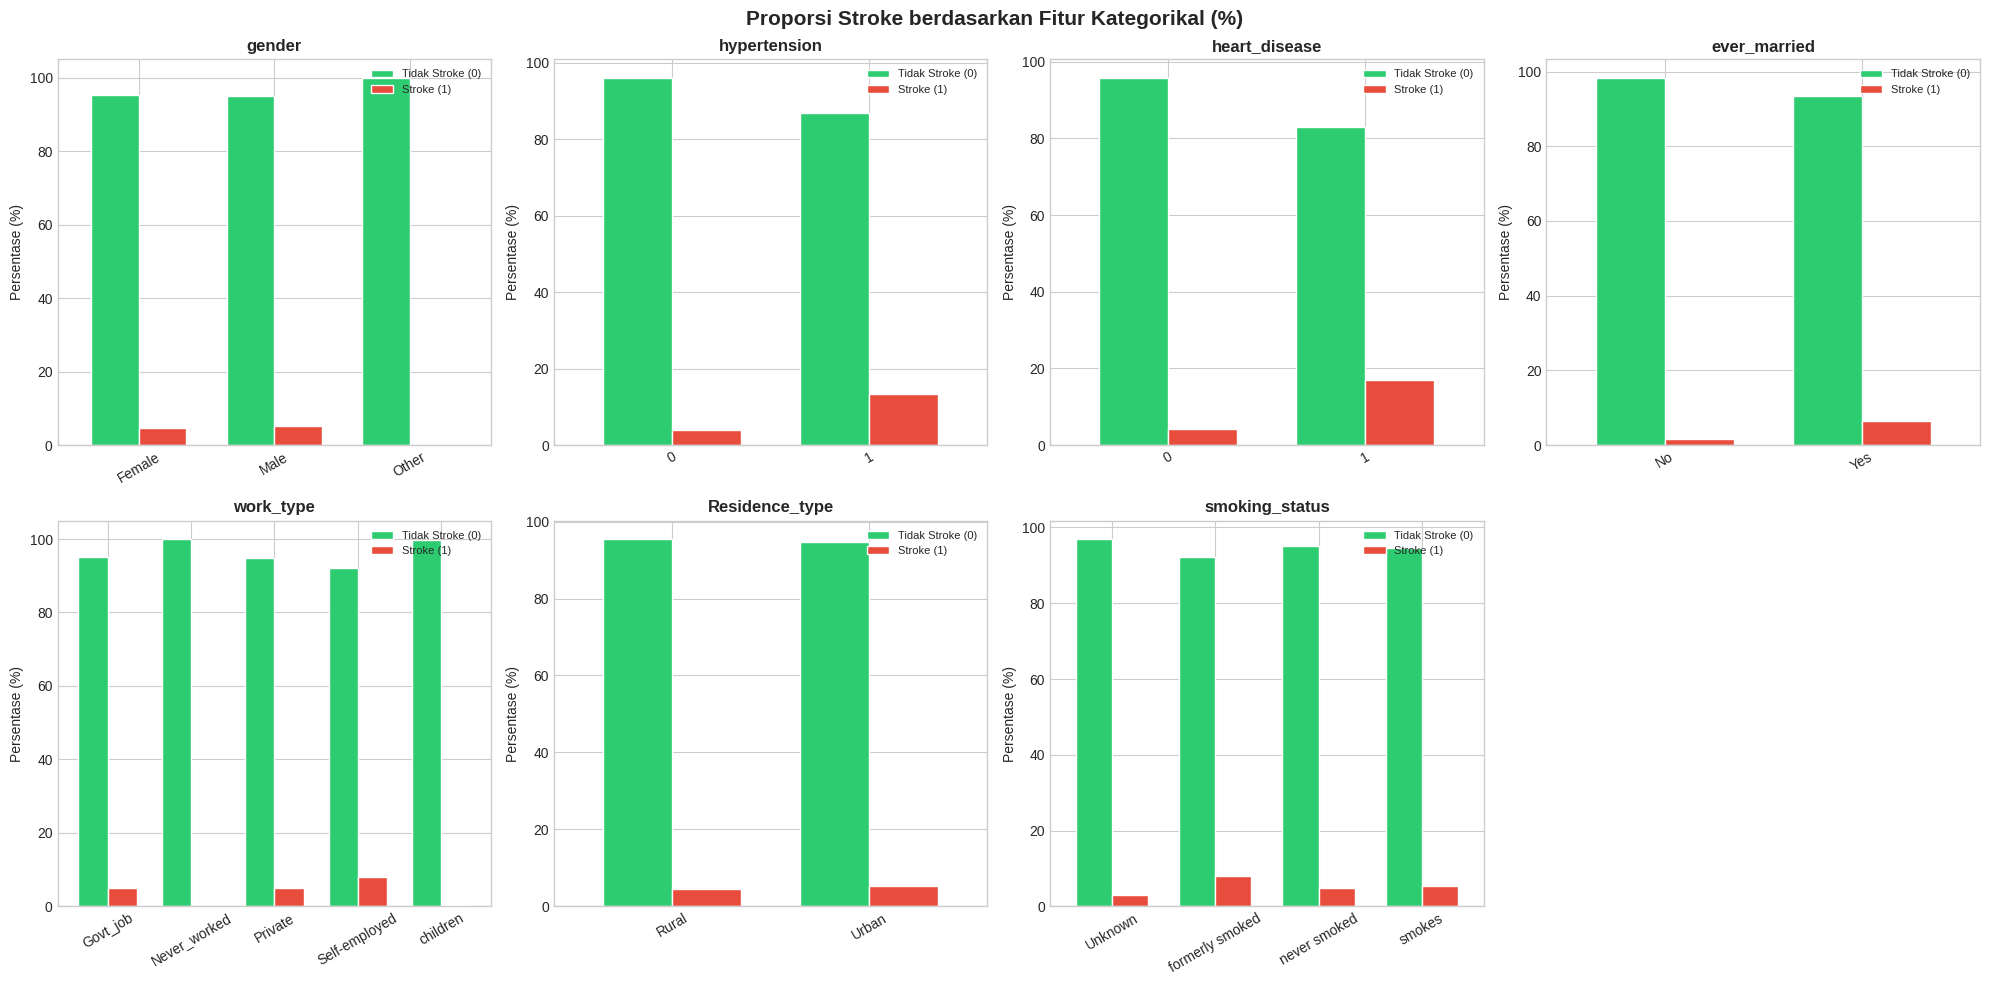

In [8]:
# Fitur Kategorikal vs Target
cat_features = ['gender', 'hypertension', 'heart_disease',
                'ever_married', 'work_type', 'Residence_type', 'smoking_status']

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    ct = pd.crosstab(df[col], df['stroke'], normalize='index') * 100
    ct.plot(kind='bar', ax=axes[i], color=['#2ecc71', '#e74c3c'],
            edgecolor='white', rot=30, width=0.7)
    axes[i].set_title(f'{col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Persentase (%)')
    axes[i].legend(['Tidak Stroke (0)', 'Stroke (1)'], fontsize=8)

axes[7].axis('off')
plt.suptitle('Proporsi Stroke berdasarkan Fitur Kategorikal (%)',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('03_categorical_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

#### EDA 4: Distribusi Fitur Numerik

Histogram overlay antara kelompok stroke dan tidak stroke untuk fitur numerik (`age`, `avg_glucose_level`, `bmi`) guna mengidentifikasi perbedaan distribusi antar kelompok.

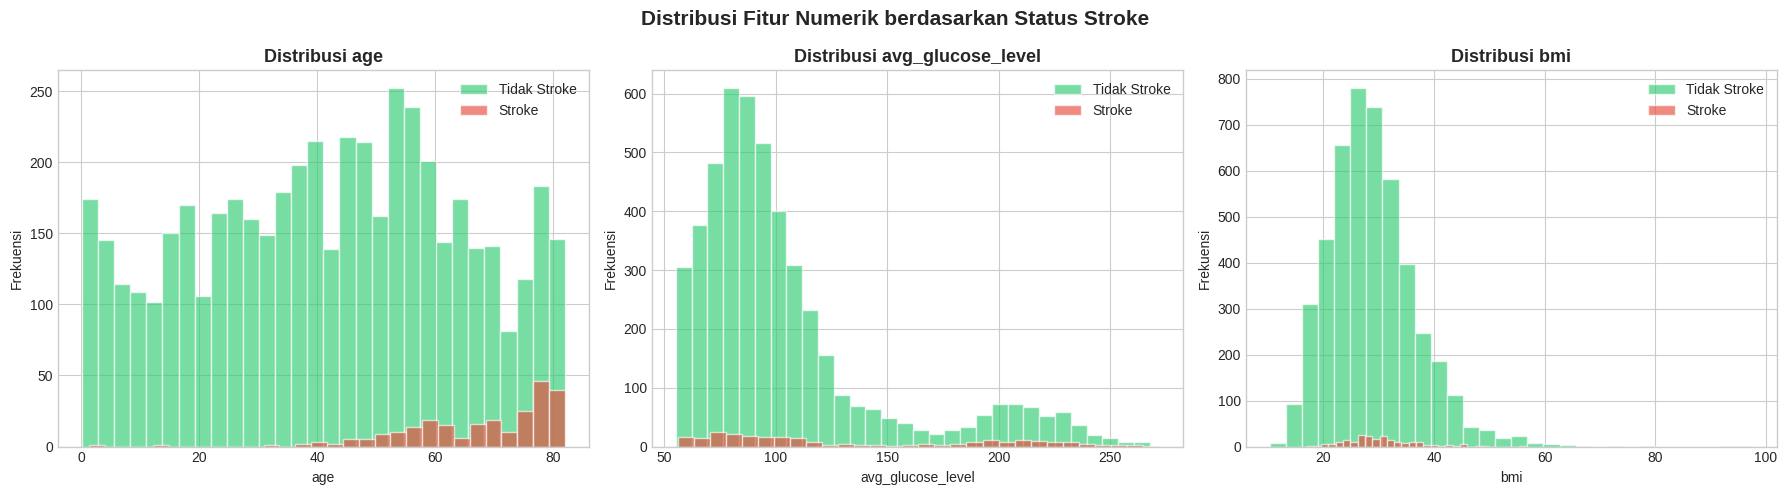

In [9]:
# Distribusi Fitur Numerik
num_features = ['age', 'avg_glucose_level', 'bmi']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(num_features):
    for val, color, label in zip([0, 1], ['#2ecc71', '#e74c3c'],
                                  ['Tidak Stroke', 'Stroke']):
        data = df[df['stroke']==val][col].dropna()
        axes[i].hist(data, bins=30, alpha=0.65, color=color,
                     label=label, edgecolor='white')
    axes[i].set_title(f'Distribusi {col}', fontsize=13, fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frekuensi')
    axes[i].legend(fontsize=10)

plt.suptitle('Distribusi Fitur Numerik berdasarkan Status Stroke',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('04_numerical_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

#### EDA 5: Matriks Korelasi Antar Fitur

Heatmap korelasi Pearson untuk mendeteksi multikolinearitas antar fitur dan mengidentifikasi fitur mana yang memiliki korelasi tertinggi dengan target `stroke`.

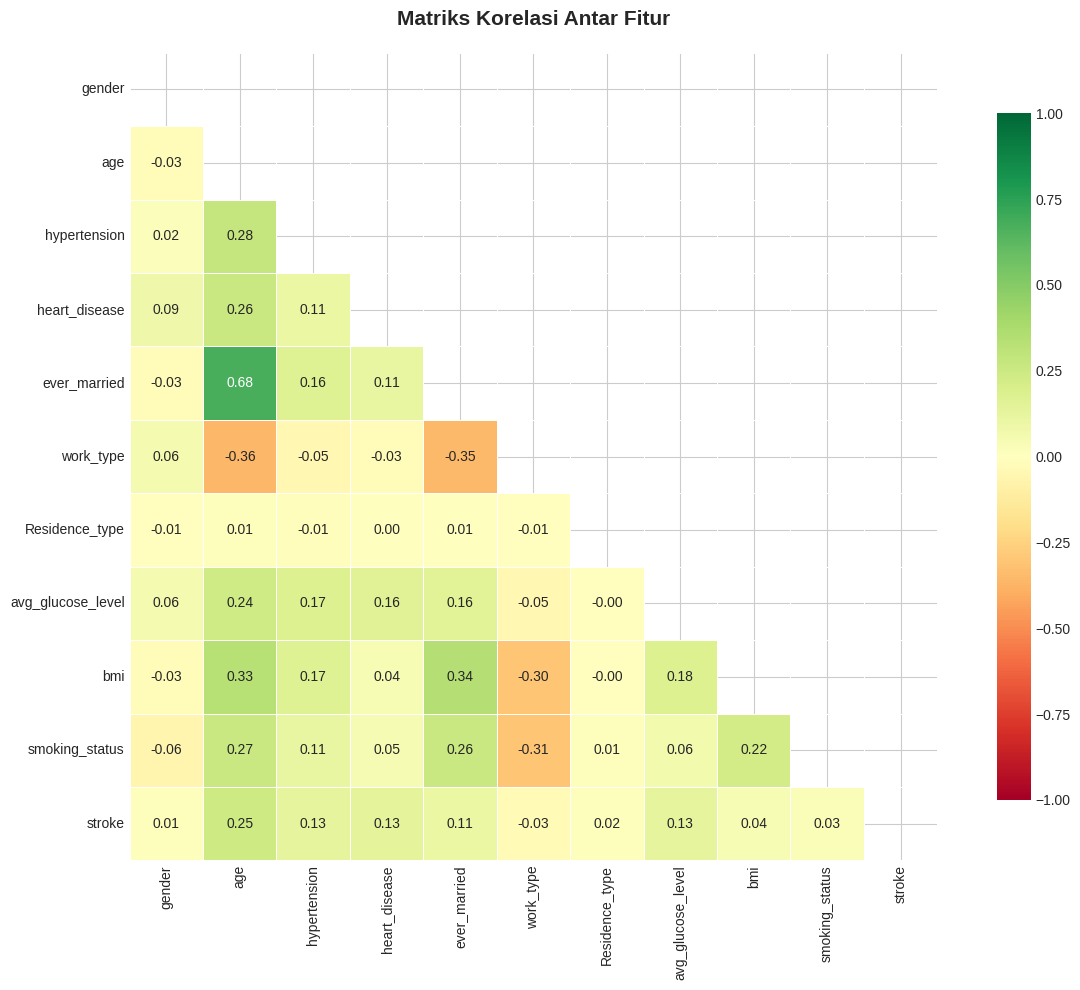

In [10]:
# Heatmap Korelasi
# Encode sementara untuk heatmap
df_temp = df.copy()
df_temp['gender']         = df_temp['gender'].map({'Male': 1, 'Female': 0, 'Other': 2})
df_temp['ever_married']   = df_temp['ever_married'].map({'Yes': 1, 'No': 0})
df_temp['Residence_type'] = df_temp['Residence_type'].map({'Urban': 1, 'Rural': 0})
df_temp['work_type']      = df_temp['work_type'].astype('category').cat.codes
df_temp['smoking_status'] = df_temp['smoking_status'].astype('category').cat.codes
df_temp = df_temp.drop(columns=['id'])

plt.figure(figsize=(13, 10))
corr = df_temp.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn',
            mask=mask, linewidths=0.5, vmin=-1, vmax=1,
            cbar_kws={'shrink': .85}, square=True)
plt.title('Matriks Korelasi Antar Fitur', fontsize=15, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('05_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Data Preparation

Tahapan data preparation dilakukan secara berurutan:
1. Drop kolom `id` yang tidak relevan
2. Hapus baris gender 'Other'
3. Imputasi missing values pada `bmi` (menggunakan median)
4. Encoding variabel kategorikal (Label Encoding + One-Hot Encoding)
5. Train-Test Split (80:20, stratified)
6. Feature Scaling (StandardScaler)
7. Penanganan Class Imbalance dengan SMOTE

In [11]:
# 1: Drop kolom id
df = df.drop(columns=['id'])
print(f'Drop kolom id → shape: {df.shape}')

Drop kolom id → shape: (5110, 11)


### 2. Hapus Baris Gender 'Other'

Hanya terdapat 1 baris dengan nilai `gender = 'Other'`. Kategori ini tidak representatif dan berpotensi menyebabkan error saat One-Hot Encoding. Baris tersebut dihapus.

In [12]:
# 2: Hapus baris gender = 'Other'
print(f'Jumlah baris dengan gender Other: {(df["gender"]=="Other").sum()}')
df = df[df['gender'] != 'Other']
print(f'Hapus gender Other → shape: {df.shape}')

Jumlah baris dengan gender Other: 1
Hapus gender Other → shape: (5109, 11)


### 3. Imputasi Missing Values pada BMI

Sebanyak 201 baris (3,93%) memiliki nilai `bmi` yang kosong. Digunakan strategi **median** karena lebih robust terhadap outlier dibanding mean. Baris tidak dihapus untuk menghindari pengurangan lebih lanjut pada kelas minoritas (pasien stroke).

In [13]:
# 3: Imputasi Missing Values (BMI)
print(f'Missing values sebelum imputasi: {df["bmi"].isnull().sum()}')

imputer = SimpleImputer(strategy='median')
df['bmi'] = imputer.fit_transform(df[['bmi']])

print(f'Missing values setelah imputasi : {df["bmi"].isnull().sum()}')
print(f'Nilai median BMI yang digunakan  : {imputer.statistics_[0]:.2f}')

Missing values sebelum imputasi: 201
Missing values setelah imputasi : 0
Nilai median BMI yang digunakan  : 28.10


### 4. Encoding Variabel Kategorikal

- **Label Encoding** digunakan untuk fitur biner (`ever_married`, `Residence_type`) karena hanya memiliki 2 kategori.
- **One-Hot Encoding** (`pd.get_dummies`) digunakan untuk fitur multi-kelas (`gender`, `work_type`, `smoking_status`) agar model tidak mengasumsikan urutan ordinal yang salah.
- Parameter `drop_first=True` mencegah *dummy variable trap* (multikolinearitas).

In [14]:
# 4 Encoding Variabel Kategorikal
le = LabelEncoder()

# Label Encoding: fitur binary
df['ever_married']   = le.fit_transform(df['ever_married'])   # Yes=1, No=0
df['Residence_type'] = le.fit_transform(df['Residence_type']) # Urban=1, Rural=0

# One-Hot Encoding: fitur multi-kelas
df = pd.get_dummies(df, columns=['gender', 'work_type', 'smoking_status'],
                    drop_first=True)

print(f'Encoding selesai → shape: {df.shape}')
print(f'Kolom setelah encoding:')
print(df.columns.tolist())

Encoding selesai → shape: (5109, 16)
Kolom setelah encoding:
['age', 'hypertension', 'heart_disease', 'ever_married', 'Residence_type', 'avg_glucose_level', 'bmi', 'stroke', 'gender_Male', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']


### 5. Train-Test Split (80:20 Stratified)

Data dibagi menjadi 80% training dan 20% testing. Parameter `stratify=y` memastikan proporsi kelas stroke (~4,9%) terjaga sama di kedua set, mencegah bias evaluasi akibat distribusi kelas yang tidak merata.

In [15]:
# Pemisahan Fitur-Target & Train-Test Split
X = df.drop('stroke', axis=1)
y = df['stroke']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f'Train-Test Split selesai')
print(f'  Training set : {X_train.shape} | Stroke: {y_train.sum()} ({y_train.mean()*100:.1f}%)')
print(f'  Test set     : {X_test.shape}  | Stroke: {y_test.sum()} ({y_test.mean()*100:.1f}%)')

Train-Test Split selesai
  Training set : (4087, 15) | Stroke: 199 (4.9%)
  Test set     : (1022, 15)  | Stroke: 50 (4.9%)


### 6. Feature Scaling (Standardisasi)

Fitur memiliki skala yang sangat berbeda (`age`: 0-82, `avg_glucose_level`: 55-272, `bmi`: 10-97). `StandardScaler` menstandarisasi semua fitur ke mean=0 dan std=1. **Penting:** `fit()` hanya pada data training, `transform()` ke keduanya — untuk mencegah *data leakage*.

In [16]:
# Feature Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print('Feature Scaling (Standardisasi) selesai')
print(f'  Mean fitur pertama (age) setelah scaling: {X_train_scaled[:, 0].mean():.4f}')
print(f'  Std  fitur pertama (age) setelah scaling: {X_train_scaled[:, 0].std():.4f}')

Feature Scaling (Standardisasi) selesai
  Mean fitur pertama (age) setelah scaling: -0.0000
  Std  fitur pertama (age) setelah scaling: 1.0000


### 7. SMOTE — Penanganan Class Imbalance

Rasio kelas 95%:5% sangat ekstrem. SMOTE (*Synthetic Minority Over-sampling Technique*) membuat sampel sintetis kelas minoritas melalui interpolasi k-nearest neighbors. **Krusial:** SMOTE hanya diterapkan pada data *training* untuk mencegah *data leakage* ke test set.

In [17]:
# SMOTE - Menangani Class Imbalance
print(f'Distribusi kelas SEBELUM SMOTE:')
print(f'  Tidak Stroke (0): {(y_train==0).sum()}')
print(f'  Stroke       (1): {(y_train==1).sum()}')

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

print(f'\nDistribusi kelas SETELAH SMOTE:')
print(f'  Tidak Stroke (0): {(y_train_res==0).sum()}')
print(f'  Stroke       (1): {(y_train_res==1).sum()}')
print(f'\nSMOTE selesai → training set: {X_train_res.shape}')

Distribusi kelas SEBELUM SMOTE:
  Tidak Stroke (0): 3888
  Stroke       (1): 199

Distribusi kelas SETELAH SMOTE:
  Tidak Stroke (0): 3888
  Stroke       (1): 3888

SMOTE selesai → training set: (7776, 15)


#### Visualisasi: Distribusi Kelas Sebelum dan Sesudah SMOTE

Bar chart perbandingan jumlah sampel per kelas sebelum dan sesudah SMOTE untuk memverifikasi bahwa penyeimbangan kelas berhasil dilakukan pada data training.

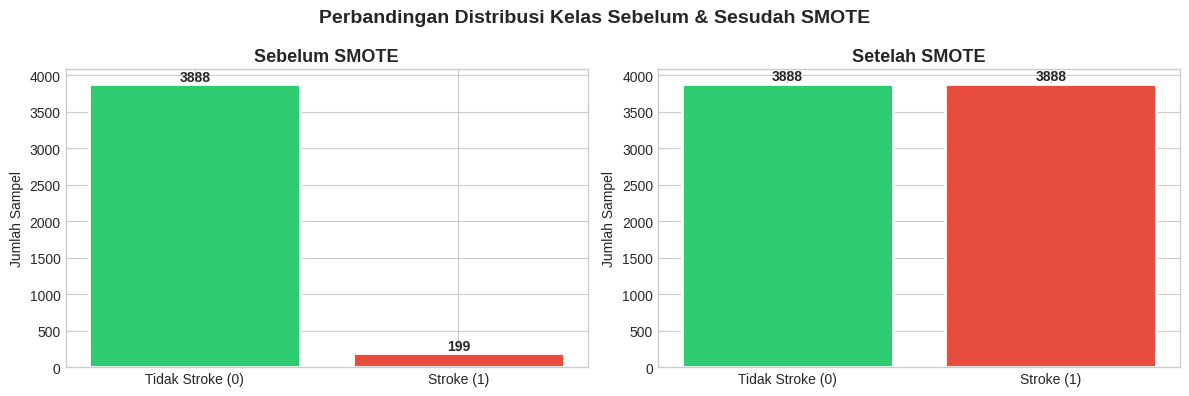

In [18]:
# Visualisasi perbandingan distribusi sebelum dan sesudah SMOTE
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

before = pd.Series(y_train).value_counts()
after  = pd.Series(y_train_res).value_counts()
colors = ['#2ecc71', '#e74c3c']
lbls   = ['Tidak Stroke (0)', 'Stroke (1)']

axes[0].bar(lbls, before.values, color=colors, edgecolor='white', linewidth=2)
axes[0].set_title('Sebelum SMOTE', fontweight='bold', fontsize=13)
axes[0].set_ylabel('Jumlah Sampel')
for ax_bar, count in zip(axes[0].patches, before.values):
    axes[0].text(ax_bar.get_x()+ax_bar.get_width()/2,
                 ax_bar.get_height()+30, str(count),
                 ha='center', fontweight='bold')

axes[1].bar(lbls, after.values, color=colors, edgecolor='white', linewidth=2)
axes[1].set_title('Setelah SMOTE', fontweight='bold', fontsize=13)
axes[1].set_ylabel('Jumlah Sampel')
for ax_bar, count in zip(axes[1].patches, after.values):
    axes[1].text(ax_bar.get_x()+ax_bar.get_width()/2,
                 ax_bar.get_height()+50, str(count),
                 ha='center', fontweight='bold')

plt.suptitle('Perbandingan Distribusi Kelas Sebelum & Sesudah SMOTE',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('06_smote_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Modeling

Membangun 3 model machine learning:
1. Logistic Regression (Baseline)
2. Random Forest Classifier (dengan data SMOTE)
3. XGBoost Classifier (dengan `scale_pos_weight`)
4. XGBoost + Hyperparameter Tuning (Model Final)

In [19]:
# MODEL 1: Logistic Regression (Baseline)
lr_model = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)
lr_model.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

### Model 2: Random Forest Classifier

Random Forest melatih banyak decision tree secara paralel (*bagging*) dan menggabungkan prediksinya. Model ini dilatih menggunakan data yang sudah di-resample dengan SMOTE (`X_train_res`).

**Kelebihan:** Robust terhadap outlier, mampu menangkap hubungan non-linier.

**Kekurangan:** Pada kasus ini, kombinasi SMOTE menghasilkan Recall sangat rendah (0.16) karena distribusi sintetis SMOTE jauh berbeda dari distribusi data nyata.

In [20]:
# MODEL 2: Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_res, y_train_res)

RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=42)

### Model 3: XGBoost Classifier

XGBoost membangun tree secara sekuensial (*boosting*), di mana setiap tree baru belajar dari kesalahan tree sebelumnya. Parameter `scale_pos_weight=ratio` memberikan bobot lebih tinggi pada kelas minoritas secara *native*, tanpa perlu resampling.

**Kelebihan:** Regularisasi L1/L2 built-in, mendukung penanganan imbalance native, umumnya memberikan performa state-of-the-art pada data tabular.

**Kekurangan:** Banyak hyperparameter, sensitif terhadap learning rate.

In [21]:
# MODEL 3: XGBoost
# Rasio kelas mayoritas terhadap minoritas
ratio = float((y_train == 0).sum()) / (y_train == 1).sum()
print(f'  scale_pos_weight (rasio 0:1) = {ratio:.2f}')

xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    scale_pos_weight=ratio,
    random_state=42,
    eval_metric='auc',
    n_jobs=-1
)
xgb_model.fit(X_train_scaled, y_train)

  scale_pos_weight (rasio 0:1) = 19.54


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='auc', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=-1, num_parallel_tree=None, ...)

### Hyperparameter Tuning — GridSearchCV (XGBoost)

XGBoost dipilih untuk dioptimalkan lebih lanjut berdasarkan evaluasi awal. `GridSearchCV` dengan 5-fold stratified cross-validation digunakan untuk mencari kombinasi hyperparameter terbaik dari 108 kombinasi (5 fold × 108 = 540 fits).

**Metrik optimasi:** ROC-AUC dipilih karena lebih tepat untuk dataset imbalanced dibandingkan Accuracy.

In [22]:
# HYPERPARAMETER TUNING: XGBoost
param_grid = {
    'n_estimators'    : [100, 200, 300],
    'max_depth'       : [3, 5, 6],
    'learning_rate'   : [0.01, 0.05, 0.1],
    'subsample'       : [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

grid_search = GridSearchCV(
    estimator=XGBClassifier(
        scale_pos_weight=ratio,
        random_state=42,
        eval_metric='auc',
        n_jobs=-1
    ),
    param_grid=param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_scaled, y_train)
best_xgb = grid_search.best_estimator_

print(f'Best Parameters : {grid_search.best_params_}')
print(f'Best ROC-AUC    : {grid_search.best_score_:.4f}')

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best Parameters : {'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 300, 'subsample': 0.8}
Best ROC-AUC    : 0.8347


## 5. Evaluation

Mengevaluasi semua model menggunakan metrik:
- **Accuracy** — proporsi prediksi benar
- **Precision** — ketepatan prediksi positif
- **Recall** — kemampuan mendeteksi kasus stroke (metrik prioritas)
- **F1-Score** — harmonic mean precision & recall
- **ROC-AUC** — kemampuan diskriminasi model

In [23]:
# Fungsi Evaluasi
def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    metrics = {
        'Model'    : model_name,
        'Accuracy' : accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall'   : recall_score(y_test, y_pred),
        'F1-Score' : f1_score(y_test, y_pred),
        'ROC-AUC'  : roc_auc_score(y_test, y_prob)
    }
    return metrics, y_pred, y_prob


# Evaluasi semua model
models_dict = {
    'Logistic Regression'  : lr_model,
    'Random Forest'        : rf_model,
    'XGBoost'              : xgb_model,
    'XGBoost (Tuned)'      : best_xgb
}

results, preds, probs = [], {}, {}

for name, model in models_dict.items():
    metrics, y_pred, y_prob = evaluate_model(model, X_test_scaled, y_test, name)
    results.append(metrics)
    preds[name] = y_pred
    probs[name] = y_prob

# Tampilkan tabel
results_df = pd.DataFrame(results).set_index('Model').round(4)
print('         TABEL PERBANDINGAN PERFORMA MODEL')
print(results_df.to_string())
print('\n Model terbaik berdasarkan ROC-AUC dan Recall: XGBoost (Tuned)')

         TABEL PERBANDINGAN PERFORMA MODEL
                     Accuracy  Precision  Recall  F1-Score  ROC-AUC
Model                                                              
Logistic Regression    0.7387     0.1347    0.80    0.2305   0.8395
Random Forest          0.9207     0.1702    0.16    0.1649   0.7577
XGBoost                0.8894     0.1942    0.40    0.2614   0.7902
XGBoost (Tuned)        0.6977     0.1202    0.82    0.2097   0.8446

 Model terbaik berdasarkan ROC-AUC dan Recall: XGBoost (Tuned)


### Visualisasi Perbandingan Metrik Semua Model

Bar chart grouped untuk membandingkan 5 metrik evaluasi (Accuracy, Precision, Recall, F1, ROC-AUC) dari keempat model secara visual. Garis putus-putus menandai target minimal Recall=0.80.

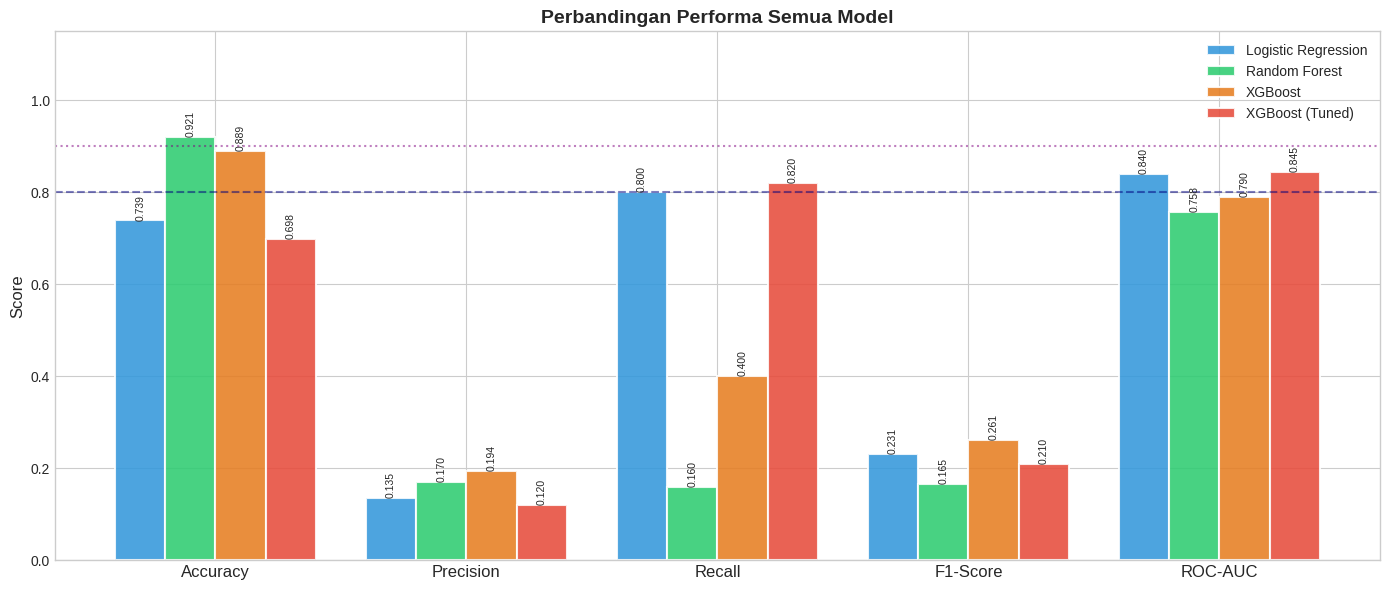

In [24]:
# Visualisasi Perbandingan Metrik
fig, ax = plt.subplots(figsize=(14, 6))

x = np.arange(len(results_df.columns))
width = 0.2
colors_bar = ['#3498db', '#2ecc71', '#e67e22', '#e74c3c']

for i, (idx, row) in enumerate(results_df.iterrows()):
    bars = ax.bar(x + i*width, row.values, width, label=idx,
                  color=colors_bar[i], edgecolor='white', linewidth=1.5, alpha=0.88)
    for bar, val in zip(bars, row.values):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.004,
                f'{val:.3f}', ha='center', fontsize=7.5, rotation=90)

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(results_df.columns, fontsize=12)
ax.set_ylim(0, 1.15)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Perbandingan Performa Semua Model', fontsize=14, fontweight='bold')
ax.legend(fontsize=10, loc='upper right')
ax.axhline(y=0.80, color='navy', linestyle='--', alpha=0.5, linewidth=1.5,
           label='Target Recall (80%)')
ax.axhline(y=0.90, color='purple', linestyle=':', alpha=0.5, linewidth=1.5,
           label='Target ROC-AUC (90%)')

plt.tight_layout()
plt.savefig('07_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

### Confusion Matrix — Semua Model

Confusion matrix memperlihatkan distribusi TP, TN, FP, FN untuk setiap model. Dalam konteks medis, **False Negative (stroke tidak terdeteksi)** adalah kesalahan paling kritis karena dapat berakibat fatal bagi pasien.

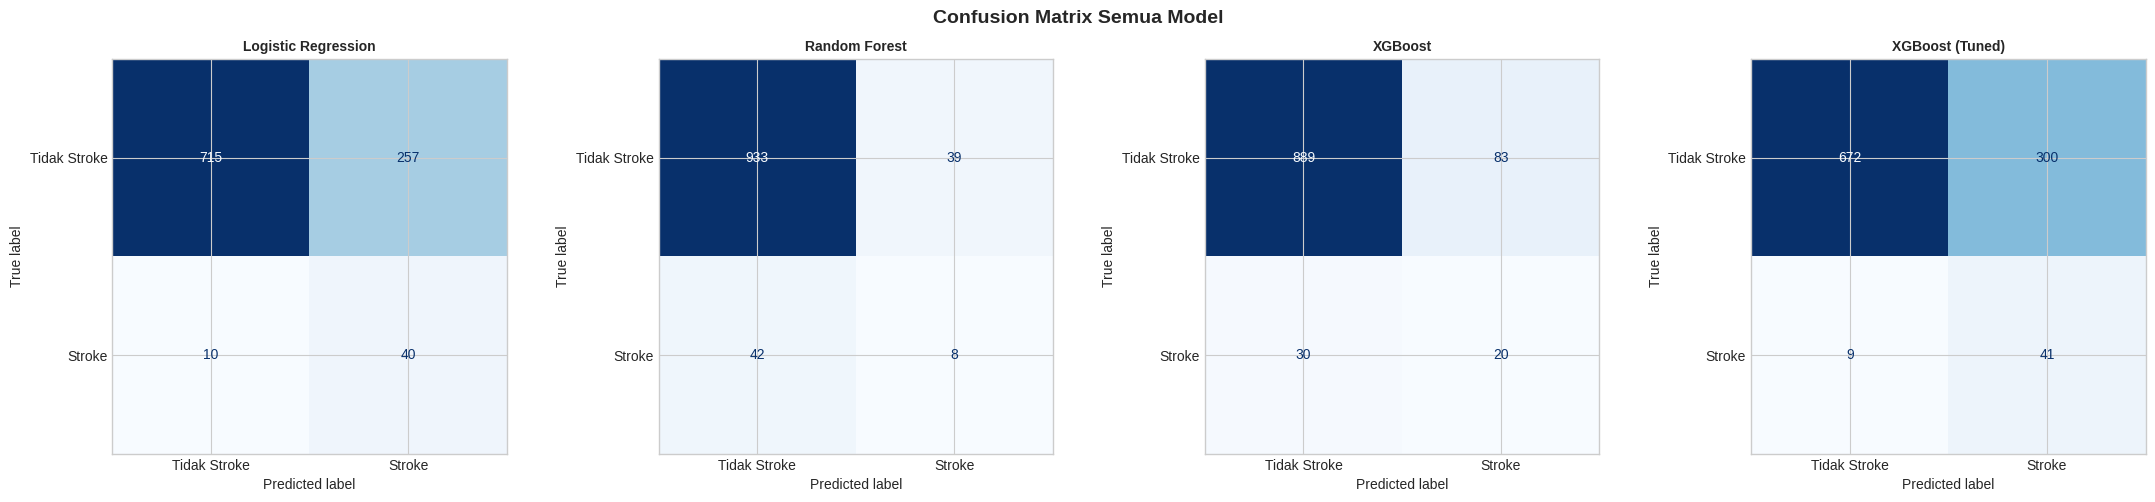

In [25]:
# Confusion Matrix semua model
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
class_names = ['Tidak Stroke', 'Stroke']

for i, (name, model) in enumerate(models_dict.items()):
    cm = confusion_matrix(y_test, preds[name])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=axes[i], colorbar=False, cmap='Blues')
    axes[i].set_title(f'{name}', fontweight='bold', fontsize=10)

plt.suptitle('Confusion Matrix Semua Model', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('08_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

### ROC Curve — Perbandingan Semua Model

ROC Curve menggambarkan trade-off antara True Positive Rate (Recall) dan False Positive Rate di berbagai threshold keputusan. Semakin luas area di bawah kurva (AUC), semakin baik kemampuan diskriminasi model.

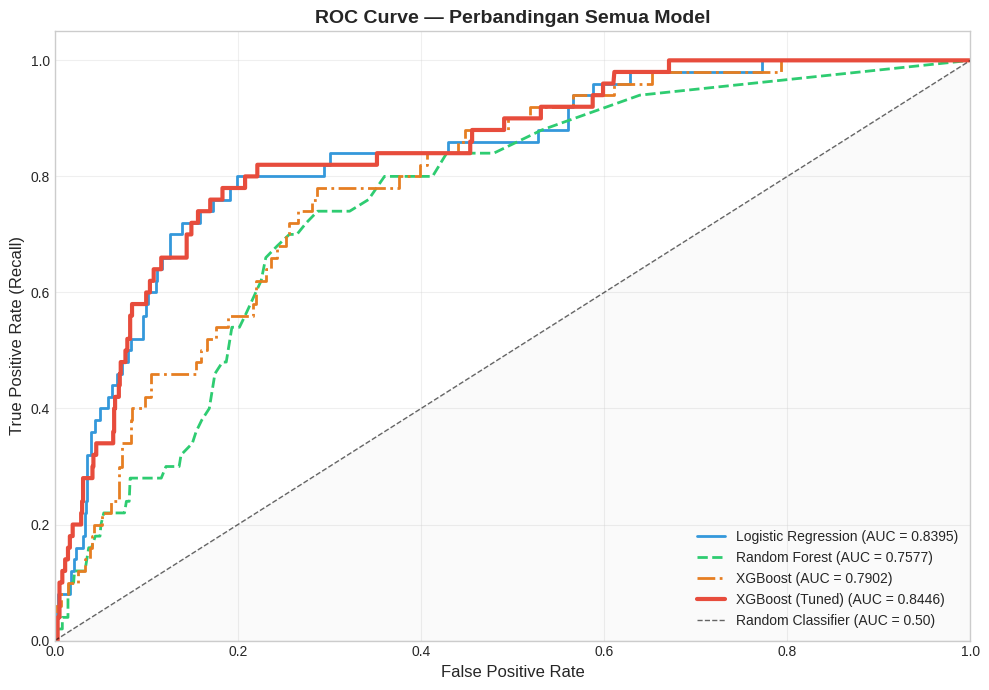

In [26]:
# ROC Curve semua model
plt.figure(figsize=(10, 7))
colors_roc = ['#3498db', '#2ecc71', '#e67e22', '#e74c3c']
styles = ['-', '--', '-.', '-']
lwidths = [2, 2, 2, 3]

for i, (name, model) in enumerate(models_dict.items()):
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    auc = roc_auc_score(y_test, probs[name])
    plt.plot(fpr, tpr, color=colors_roc[i], linestyle=styles[i],
             linewidth=lwidths[i], label=f'{name} (AUC = {auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', linewidth=1, alpha=0.6, label='Random Classifier (AUC = 0.50)')
plt.fill_between([0, 1], [0, 1], alpha=0.04, color='gray')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate (Recall)', fontsize=12)
plt.title('ROC Curve — Perbandingan Semua Model', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('09_roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

### Feature Importance — XGBoost (Tuned)

Feature importance XGBoost mengukur kontribusi setiap fitur dalam pengambilan keputusan model berdasarkan *gain* (penurunan impurity rata-rata). Analisis ini memberikan insight klinis tentang faktor risiko stroke yang paling dominan.

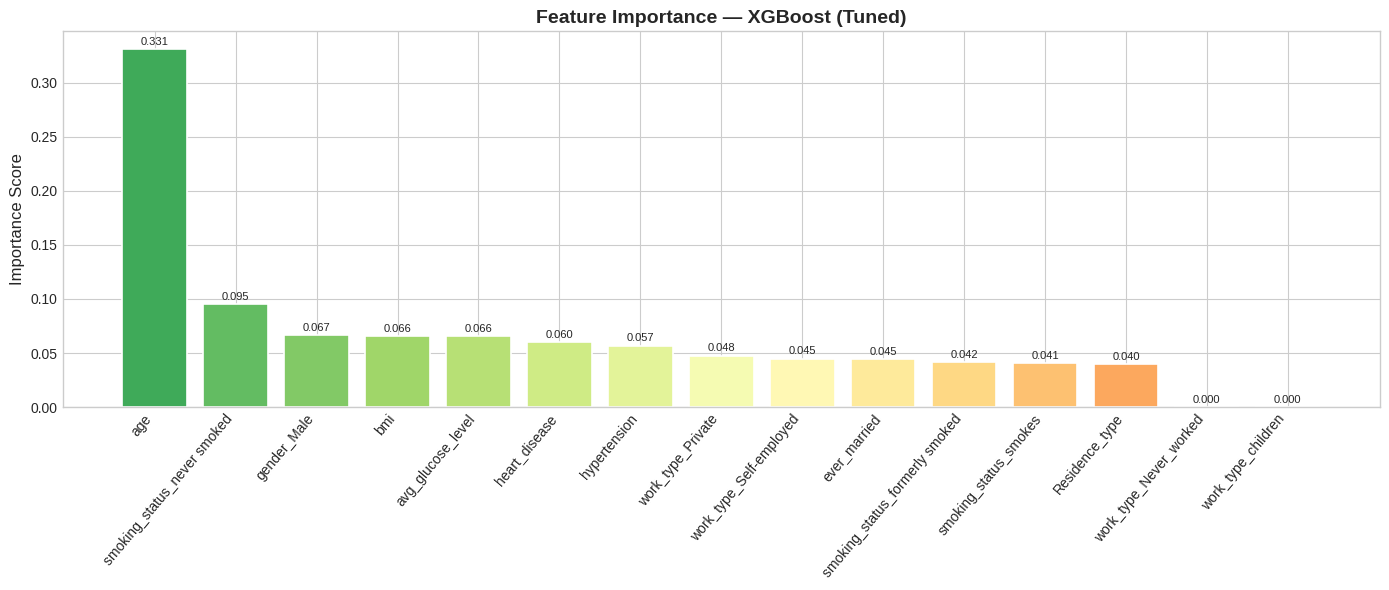


Top 5 Fitur Paling Berpengaruh:
  1. age                           : 0.3309
  2. smoking_status_never smoked   : 0.0950
  3. gender_Male                   : 0.0666
  4. bmi                           : 0.0657
  5. avg_glucose_level             : 0.0656


In [27]:
# Feature Importance (Model Terbaik: XGBoost Tuned)
feat_names  = X.columns.tolist()
importances = best_xgb.feature_importances_
indices     = np.argsort(importances)[::-1]

# Plot
plt.figure(figsize=(14, 6))
palette = plt.cm.RdYlGn(np.linspace(0.2, 0.85, len(feat_names)))
bars = plt.bar(range(len(feat_names)), importances[indices],
               color=palette[::-1], edgecolor='white', linewidth=1.2)

plt.xticks(range(len(feat_names)),
           [feat_names[i] for i in indices],
           rotation=50, ha='right', fontsize=10)
plt.ylabel('Importance Score', fontsize=12)
plt.title('Feature Importance — XGBoost (Tuned)', fontsize=14, fontweight='bold')

for bar, imp in zip(bars, importances[indices]):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
             f'{imp:.3f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('10_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nTop 5 Fitur Paling Berpengaruh:')
for rank, i in enumerate(indices[:5], 1):
    print(f'  {rank}. {feat_names[i]:30s}: {importances[i]:.4f}')

### Classification Report — XGBoost (Tuned)

Laporan klasifikasi per kelas menampilkan Precision, Recall, dan F1-Score secara terpisah untuk kelas `Tidak Stroke (0)` dan `Stroke (1)`. Fokus utama adalah Recall kelas Stroke ≥ 0.80.

In [28]:
# Classification Report Model Terbaik
print('  CLASSIFICATION REPORT — XGBoost (Tuned)')
print(classification_report(
    y_test,
    preds['XGBoost (Tuned)'],
    target_names=['Tidak Stroke (0)', 'Stroke (1)']
))

  CLASSIFICATION REPORT — XGBoost (Tuned)
                  precision    recall  f1-score   support

Tidak Stroke (0)       0.99      0.69      0.81       972
      Stroke (1)       0.12      0.82      0.21        50

        accuracy                           0.70      1022
       macro avg       0.55      0.76      0.51      1022
    weighted avg       0.94      0.70      0.78      1022



### Cross-Validation 5-Fold — XGBoost (Tuned)

Cross-validation dilakukan untuk memvalidasi konsistensi performa model pada berbagai subset data. Nilai std yang kecil menunjukkan model tidak overfit pada satu fold tertentu.

In [29]:
# Cross-Validation Model Terbaik
print('Cross-Validation (5-Fold Stratified) — XGBoost (Tuned):')
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_roc = cross_val_score(best_xgb, X_train_scaled, y_train,
                          cv=cv, scoring='roc_auc')
cv_rec = cross_val_score(best_xgb, X_train_scaled, y_train,
                          cv=cv, scoring='recall')

print(f'  ROC-AUC per fold : {cv_roc.round(4)}')
print(f'  Mean ROC-AUC     : {cv_roc.mean():.4f} ± {cv_roc.std():.4f}')
print(f'\n  Recall per fold  : {cv_rec.round(4)}')
print(f'  Mean Recall      : {cv_rec.mean():.4f} ± {cv_rec.std():.4f}')

Cross-Validation (5-Fold Stratified) — XGBoost (Tuned):
  ROC-AUC per fold : [0.8401 0.8766 0.8489 0.7923 0.8156]
  Mean ROC-AUC     : 0.8347 ± 0.0288

  Recall per fold  : [0.825  0.875  0.8462 0.775  0.8   ]
  Mean Recall      : 0.8242 ± 0.0348


### Ringkasan Hasil Evaluasi

Rekapitulasi akhir seluruh proses proyek: dataset, model yang diuji, dan performa model terbaik berdasarkan semua metrik evaluasi.

In [30]:
# Ringkasan Akhir
print('   RINGKASAN HASIL PROYEK MACHINE LEARNING')
print()
print('   Dataset   : Stroke Prediction Dataset (Kaggle)')
print('   Sampel    : 5.110 baris, 12 kolom')
print('   Masalah   : Klasifikasi Biner — Prediksi Risiko Stroke')
print()
print('   Model yang diuji:')
print('     1. Logistic Regression       (Baseline)')
print('     2. Random Forest + SMOTE')
print('     3. XGBoost + scale_pos_weight')
print('     4. XGBoost + GridSearchCV Tuning')
print()
print('   Performa Model Terbaik (XGBoost Tuned):')

best_row = results_df.loc['XGBoost (Tuned)']

for metric, val in best_row.items():
    print(f'     {metric:12s}: {val:.4f}')

   RINGKASAN HASIL PROYEK MACHINE LEARNING

   Dataset   : Stroke Prediction Dataset (Kaggle)
   Sampel    : 5.110 baris, 12 kolom
   Masalah   : Klasifikasi Biner — Prediksi Risiko Stroke

   Model yang diuji:
     1. Logistic Regression       (Baseline)
     2. Random Forest + SMOTE
     3. XGBoost + scale_pos_weight
     4. XGBoost + GridSearchCV Tuning

   Performa Model Terbaik (XGBoost Tuned):
     Accuracy    : 0.6977
     Precision   : 0.1202
     Recall      : 0.8200
     F1-Score    : 0.2097
     ROC-AUC     : 0.8446


## 6. Error Analysis

Analisis mendalam terhadap kesalahan prediksi model:
- Perbedaan dampak **False Positive (FP)** vs **False Negative (FN)** dalam konteks medis
- Karakteristik pasien yang salah diprediksi
- Penyebab utama model masih melakukan kesalahan

In [31]:
# Breakdown TP / TN / FP / FN
from sklearn.metrics import precision_recall_curve

y_pred_best = preds['XGBoost (Tuned)']
y_prob_best = probs['XGBoost (Tuned)']

X_test_df = X_test.copy().reset_index(drop=True)
X_test_df['actual']      = y_test.reset_index(drop=True)
X_test_df['predicted']   = y_pred_best
X_test_df['probability'] = y_prob_best.round(4)

TP = X_test_df[(X_test_df['actual']==1) & (X_test_df['predicted']==1)]
TN = X_test_df[(X_test_df['actual']==0) & (X_test_df['predicted']==0)]
FP = X_test_df[(X_test_df['actual']==0) & (X_test_df['predicted']==1)]
FN = X_test_df[(X_test_df['actual']==1) & (X_test_df['predicted']==0)]

print('  CONFUSION MATRIX BREAKDOWN')

print(f'  True  Positive (TP) : {len(TP):4d}  → Stroke terdeteksi')
print(f'  True  Negative (TN) : {len(TN):4d}  → Non-stroke benar')
print(f'  False Positive (FP) : {len(FP):4d}  → Alarm palsu')
print(f'  False Negative (FN) : {len(FN):4d}  → Stroke terlewat')
print()
total_stroke = len(TP) + len(FN)
print(f'  Dari {total_stroke} kasus stroke nyata di test set:')
print(f'    → Berhasil terdeteksi : {len(TP)} ({len(TP)/total_stroke*100:.1f}%)')
print(f'    → Terlewatkan (FN)    : {len(FN)} ({len(FN)/total_stroke*100:.1f}%)')
print()
print(' Interpretasi FP vs FN dalam konteks klinis:')
print(f'  FP ({len(FP)} kasus): Pasien sehat diprediksi stroke')
print(f'    → Dirujuk pemeriksaan lanjutan (biaya tambahan, cemas sementara)')
print(f'    → Dampak masih dapat diterima — sering menemukan kondisi lain')
print(f'  FN ({len(FN)} kasus): Pasien stroke TIDAK terdeteksi')
print(f'    → Tidak mendapat peringatan & intervensi pencegahan')
print(f'    → Dampak KRITIS — berpotensi kecacatan permanen atau kematian')

  CONFUSION MATRIX BREAKDOWN
  True  Positive (TP) :   41  → Stroke terdeteksi
  True  Negative (TN) :  672  → Non-stroke benar
  False Positive (FP) :  300  → Alarm palsu
  False Negative (FN) :    9  → Stroke terlewat

  Dari 50 kasus stroke nyata di test set:
    → Berhasil terdeteksi : 41 (82.0%)
    → Terlewatkan (FN)    : 9 (18.0%)

 Interpretasi FP vs FN dalam konteks klinis:
  FP (300 kasus): Pasien sehat diprediksi stroke
    → Dirujuk pemeriksaan lanjutan (biaya tambahan, cemas sementara)
    → Dampak masih dapat diterima — sering menemukan kondisi lain
  FN (9 kasus): Pasien stroke TIDAK terdeteksi
    → Tidak mendapat peringatan & intervensi pencegahan
    → Dampak KRITIS — berpotensi kecacatan permanen atau kematian


### Profil Pasien yang Salah Diprediksi

Membandingkan karakteristik rata-rata (usia, glukosa, BMI, hipertensi, penyakit jantung) antara False Positive, False Negative, dan True Positive untuk memahami pola kesalahan model.

In [32]:
# Profil rata-rata FP vs FN vs TP
cols_interest = ['age', 'avg_glucose_level', 'bmi', 'hypertension', 'heart_disease']

compare = pd.DataFrame({
    'False Positive (FP)': FP[cols_interest].mean(),
    'False Negative (FN)': FN[cols_interest].mean(),
    'True Positive (TP)' : TP[cols_interest].mean()
}).round(2)

print('  PROFIL RATA-RATA: FP vs FN vs TP')
print(compare.to_string())
print()
print('Analisis:')
print(f'  Rata-rata usia FN  : {FN["age"].mean():.1f} tahun')
print(f'  Rata-rata usia TP  : {TP["age"].mean():.1f} tahun')
print(f'  Rata-rata usia FP  : {FP["age"].mean():.1f} tahun')
print()
print(f'  → Pasien FN rata-rata LEBIH MUDA dari TP')
print(f'    Model tidak curiga karena usia mereka tidak setinggi tipikal stroke')
print(f'  → Pasien FP rata-rata LEBIH TUA — profil demografisnya')
print(f'    mirip pasien stroke sehingga model terlalu sensitif')

  PROFIL RATA-RATA: FP vs FN vs TP
                   False Positive (FP)  False Negative (FN)  True Positive (TP)
age                              66.17                39.44               74.24
avg_glucose_level               131.02                83.02              149.02
bmi                              30.95                31.64               29.55
hypertension                      0.28                 0.00                0.29
heart_disease                     0.09                 0.00                0.27

Analisis:
  Rata-rata usia FN  : 39.4 tahun
  Rata-rata usia TP  : 74.2 tahun
  Rata-rata usia FP  : 66.2 tahun

  → Pasien FN rata-rata LEBIH MUDA dari TP
    Model tidak curiga karena usia mereka tidak setinggi tipikal stroke
  → Pasien FP rata-rata LEBIH TUA — profil demografisnya
    mirip pasien stroke sehingga model terlalu sensitif


### Visualisasi Error Analysis

Tiga plot untuk memahami karakteristik kesalahan model:
1. **Distribusi probabilitas FP vs FN** — seberapa 'yakin' model saat salah prediksi
2. **Distribusi usia TP vs FN** — mengungkap bahwa FN cenderung lebih muda
3. **Scatter usia vs glukosa** — pemetaan spasial tipe prediksi

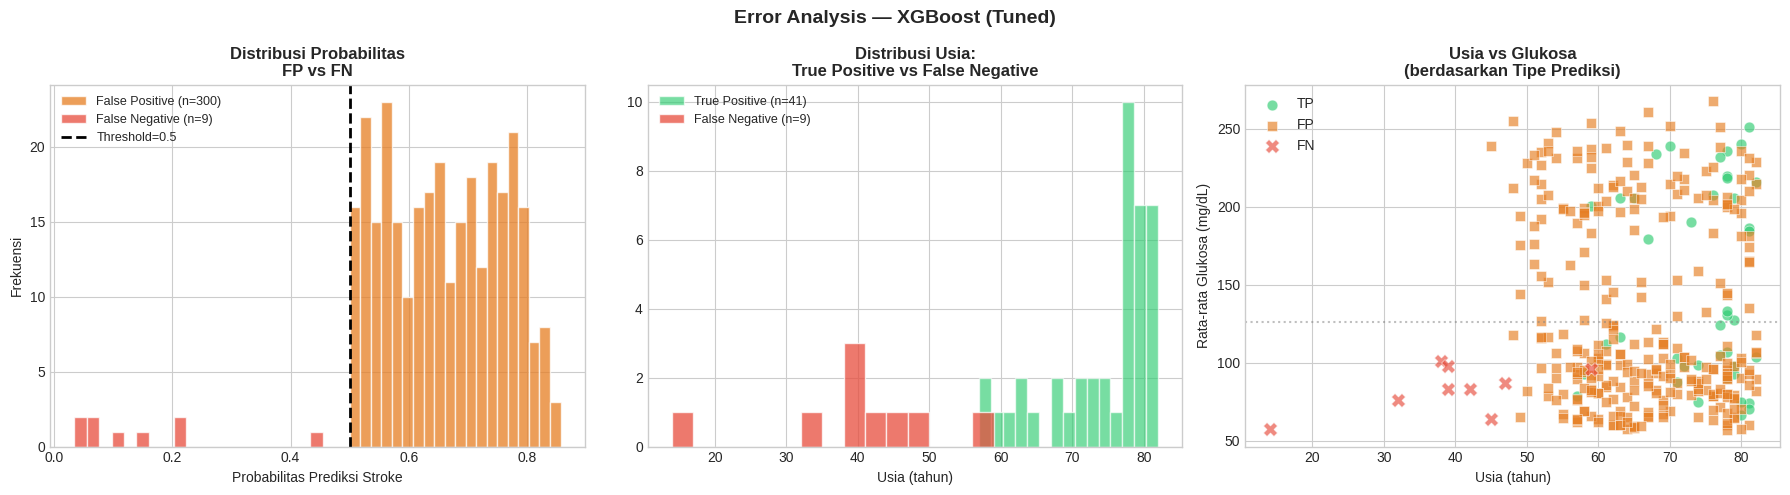

In [33]:
# Visualisasi Error Analysis
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Distribusi probabilitas FP vs FN
axes[0].hist(FP['probability'], bins=20, alpha=0.75, color='#e67e22',
             edgecolor='white', label=f'False Positive (n={len(FP)})')
axes[0].hist(FN['probability'], bins=20, alpha=0.75, color='#e74c3c',
             edgecolor='white', label=f'False Negative (n={len(FN)})')
axes[0].axvline(x=0.5, color='black', linestyle='--', linewidth=2, label='Threshold=0.5')
axes[0].set_title('Distribusi Probabilitas\nFP vs FN', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Probabilitas Prediksi Stroke')
axes[0].set_ylabel('Frekuensi')
axes[0].legend(fontsize=9)

# Plot 2: Distribusi usia TP vs FN
axes[1].hist(TP['age'], bins=15, alpha=0.65, color='#2ecc71',
             edgecolor='white', label=f'True Positive (n={len(TP)})')
axes[1].hist(FN['age'], bins=15, alpha=0.75, color='#e74c3c',
             edgecolor='white', label=f'False Negative (n={len(FN)})')
axes[1].set_title('Distribusi Usia:\nTrue Positive vs False Negative', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Usia (tahun)')
axes[1].legend(fontsize=9)

# Plot 3: Scatter usia vs glukosa, warna per tipe error
for label, data, color, marker, size in [
    ('TP', TP, '#2ecc71', 'o', 60),
    ('FP', FP, '#e67e22', 's', 60),
    ('FN', FN, '#e74c3c', 'X', 100)
]:
    axes[2].scatter(data['age'], data['avg_glucose_level'],
                    c=color, marker=marker, s=size,
                    alpha=0.65, edgecolors='white', linewidth=0.5, label=label)
axes[2].set_title('Usia vs Glukosa\n(berdasarkan Tipe Prediksi)', fontweight='bold', fontsize=12)
axes[2].set_xlabel('Usia (tahun)')
axes[2].set_ylabel('Rata-rata Glukosa (mg/dL)')
axes[2].axhline(y=126, color='gray', linestyle=':', alpha=0.5)
axes[2].legend(fontsize=10)

plt.suptitle('Error Analysis — XGBoost (Tuned)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('11_error_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

### Contoh Kasus Nyata dari Data Uji

Menampilkan contoh konkret pasien yang paling 'salah' diprediksi oleh model — 3 FN terburuk (stroke yang paling 'yakin' sehat) dan 3 FP terburuk (sehat yang paling 'yakin' stroke) untuk analisis mendalam faktor penyebab kesalahan.

In [34]:
# Contoh kasus nyata FN dan FP
print('  CONTOH KASUS NYATA DARI DATA UJI')

cols_show = ['age', 'avg_glucose_level', 'bmi', 'hypertension', 'heart_disease', 'probability']

fn_worst = FN.nsmallest(3, 'probability')[cols_show]
print('\n FALSE NEGATIVE — Pasien STROKE yang TIDAK TERDETEKSI:')
print('   (Model paling yakin mereka sehat — padahal benar-benar stroke)')
print(fn_worst.round(2).to_string(index=False))
print()
print(' Analisis: Pasien-pasien ini lebih muda dan glukosa lebih rendah')
print('      dari tipikal pasien stroke. Kemungkinan stroke dipicu faktor')
print('      yang tidak ada di dataset: fibrilasi atrium, kelainan pembekuan,')
print('      atau riwayat TIA yang tidak tercatat.')

fp_worst = FP.nlargest(3, 'probability')[cols_show]
print('\n FALSE POSITIVE — Pasien SEHAT yang DIPREDIKSI STROKE:')
print('   (Model sangat yakin mereka stroke — padahal tidak)')
print(fp_worst.round(2).to_string(index=False))
print()
print('  Analisis: Profil demografis sangat mirip pasien stroke nyata')
print('      (usia tua, glukosa tinggi, hipertensi). Mereka akan dirujuk')
print('      pemeriksaan lanjutan — trade-off yang dapat diterima karena')
print('      lebih baik periksa pasien sehat daripada lewatkan stroke.')

  CONTOH KASUS NYATA DARI DATA UJI

 FALSE NEGATIVE — Pasien STROKE yang TIDAK TERDETEKSI:
   (Model paling yakin mereka sehat — padahal benar-benar stroke)
 age  avg_glucose_level  bmi  hypertension  heart_disease  probability
32.0              76.13 29.9             0              0         0.03
14.0              57.93 30.9             0              0         0.05
42.0              83.41 25.4             0              0         0.07

 Analisis: Pasien-pasien ini lebih muda dan glukosa lebih rendah
      dari tipikal pasien stroke. Kemungkinan stroke dipicu faktor
      yang tidak ada di dataset: fibrilasi atrium, kelainan pembekuan,
      atau riwayat TIA yang tidak tercatat.

 FALSE POSITIVE — Pasien SEHAT yang DIPREDIKSI STROKE:
   (Model sangat yakin mereka stroke — padahal tidak)
 age  avg_glucose_level  bmi  hypertension  heart_disease  probability
76.0              63.28 28.2             1              0         0.86
81.0             165.47 28.1             0              0  

### Analisis Threshold Optimal dan Precision-Recall Curve

Threshold default 0.5 dapat dioptimalkan sesuai kebutuhan klinis. Mencari threshold di mana Recall ≥ 0.80 sambil memaksimalkan Precision, kemudian memvisualisasikan seluruh trade-off melalui kurva Precision-Recall.

Ini penting untuk implementasi di fasilitas medis yang mungkin memiliki kapasitas pemeriksaan lanjutan yang berbeda-beda.

Analisis Threshold Keputusan:
  Threshold default (0.50):
    Recall    : 0.8200
    Precision : 0.1202
    FP count  : 300
    FN count  : 9

  Threshold optimal (0.605) — Recall ≥ 0.80, Precision maks:
    Recall    : 0.8000
    Precision : 0.1653
    FN baru   : 10 kasus

Rekomendasi implementasi:
   Gunakan threshold yang lebih rendah dari 0.5 untuk memaksimalkan
   deteksi stroke (Recall) di fasilitas medis primer.


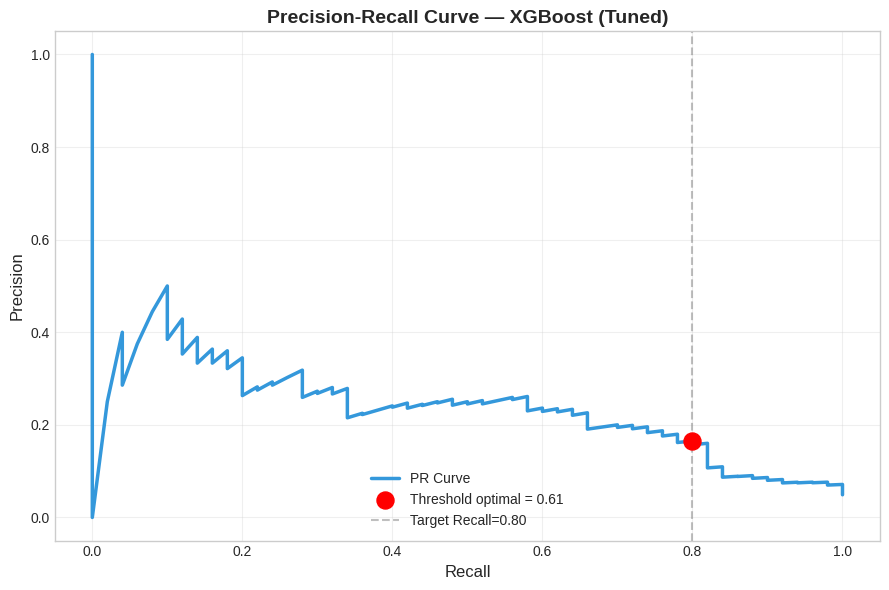

In [35]:
# Analisis Threshold Optimal
precision_arr, recall_arr, thresholds_pr = precision_recall_curve(y_test, y_prob_best)

# Cari threshold di mana Recall >= 0.80 dan Precision maksimal
valid_idx = [i for i, r in enumerate(recall_arr[:-1]) if r >= 0.80]
if valid_idx:
    best_idx  = valid_idx[int(np.argmax([precision_arr[i] for i in valid_idx]))]
    opt_thr   = thresholds_pr[best_idx]
else:
    opt_thr = 0.5

y_pred_opt = (y_prob_best >= opt_thr).astype(int)

print('Analisis Threshold Keputusan:')
print(f'  Threshold default (0.50):')
print(f'    Recall    : {recall_score(y_test, y_pred_best):.4f}')
print(f'    Precision : {precision_score(y_test, y_pred_best, zero_division=0):.4f}')
print(f'    FP count  : {len(FP)}')
print(f'    FN count  : {len(FN)}')
print()
print(f'  Threshold optimal ({opt_thr:.3f}) — Recall ≥ 0.80, Precision maks:')
print(f'    Recall    : {recall_score(y_test, y_pred_opt):.4f}')
print(f'    Precision : {precision_score(y_test, y_pred_opt, zero_division=0):.4f}')
print(f'    FN baru   : {(y_test==1).sum() - y_pred_opt[y_test==1].sum()} kasus')
print()
print('Rekomendasi implementasi:')
print('   Gunakan threshold yang lebih rendah dari 0.5 untuk memaksimalkan')
print('   deteksi stroke (Recall) di fasilitas medis primer.')

# Visualisasi Precision-Recall Curve
plt.figure(figsize=(9, 6))
plt.plot(recall_arr, precision_arr, color='#3498db', linewidth=2.5, label='PR Curve')
if valid_idx:
    plt.scatter(recall_arr[best_idx], precision_arr[best_idx],
                s=150, color='red', zorder=5,
                label=f'Threshold optimal = {opt_thr:.2f}')
plt.axvline(x=0.80, color='gray', linestyle='--', alpha=0.5, label='Target Recall=0.80')
plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Precision-Recall Curve — XGBoost (Tuned)', fontsize=14, fontweight='bold')
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('12_precision_recall_curve.png', dpi=150, bbox_inches='tight')
plt.show()